Projection maps showing the multi-model mean change per degree of global warming, with stippling to indicate the level of model agreement on the direction of change. Based on Figure 3 of [Fischer et al 2014](https://doi.org/10.1002/2014GL062018).

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cmocean

In [2]:
west_lon = 100
east_lon = 190
south_lat = -50
north_lat = 0

## Read precipitation data

In [3]:
hist_pr_file = 'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r1i1p1f1_185001-202212.nc'
scen7h_pr_file = 'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r1i1p1f1_202201-210012.nc'

In [4]:
def annual_aggregation(da):
    """Annual aggregation of monthly data"""

    da_annual = da.resample(time='YE-DEC').sum(dim='time', min_count=12, keep_attrs=True)
    years = da_annual.time.dt.year
    da_annual = da_annual.assign_coords(year=years).swap_dims({"time": "year"}).drop_vars("time")
    da_annual['season'] = 'Annual'

    return da_annual


def seasonal_aggregation(da):
    """Seasonal aggregation of monthly data"""

    da_seasonal = da.resample(time='QE-NOV').sum(dim='time', min_count=3, keep_attrs=True)    
    months = da_seasonal.time.dt.month
    da_out_dict = {}
    da_out_dict['DJF'] = da_seasonal.sel({'time': months.isin([2])}).isel(time=slice(0, -1))
    da_out_dict['MAM'] = da_seasonal.sel({'time': months.isin([5])})
    da_out_dict['JJA'] = da_seasonal.sel({'time': months.isin([8])})
    da_out_dict['SON'] = da_seasonal.sel({'time': months.isin([11])})
    da_out_list = []
    for season, da_out in da_out_dict.items():
        years = da_out.time.dt.year
        da_out = da_out.assign_coords(year=years).swap_dims({"time": "year"}).drop_vars("time")
        da_out['season'] = season
        da_out_list.append(da_out)

    return da_out_list


def temporal_aggregation(hist_file, scen_file):
    """Read and temporally aggregate precipitation data"""
    
    ds = xr.open_mfdataset([hist_file, scen_file], combine="nested", concat_dim="time")
    ds = ds.drop_duplicates(dim="time")
    ds['pr'] = ds['pr'] * 86400
    ds['pr'] = ds['pr'] * ds.time.dt.days_in_month
    ds['pr'].attrs['units'] = 'mm'

    da_annual = annual_aggregation(ds['pr'])
    da_seasonal_list = seasonal_aggregation(ds['pr'])
    da_aggregation = xr.concat([da_annual] + da_seasonal_list, dim='season')
    
    return da_aggregation

In [5]:
da_pr = temporal_aggregation(hist_pr_file, scen7h_pr_file)
da_pr = da_pr.compute()

In [6]:
da_pr_ave = da_pr.mean(dim='year', keep_attrs=True)

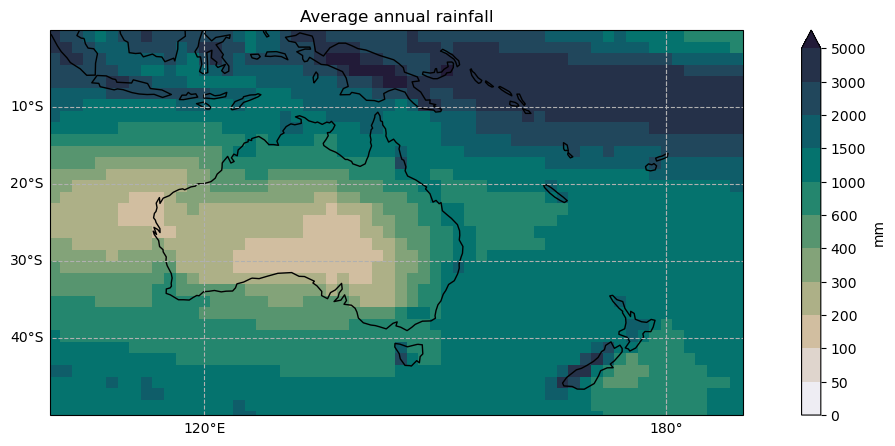

In [7]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))

levels = [0, 50, 100, 200, 300, 400, 600, 1000, 1500, 2000, 3000, 5000]
plot1 = da_pr_ave.sel({'season': 'Annual'}).plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=levels,
    extend='max',
    cmap=cmocean.cm.rain,
    cbar_kwargs={'label': 'mm'},
)
cbar1 = plot1.colorbar
cbar1.set_ticks(levels, labels=levels)
ax1.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('Average annual rainfall')
plt.show()

## Read temperature data

In [8]:
hist_tas_file = 'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r1i1p1f1_185001-202212.nc'
scen7h_tas_file = 'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r1i1p1f1_202201-210012.nc'

In [9]:
def calc_annual_gmst(hist_file, scen_file):
    """Read surface temperature data and calculate annual global mean surface temperature timeseries"""
    
    ds = xr.open_mfdataset([hist_file, scen_file], combine="nested", concat_dim="time")
    ds = ds.drop_duplicates(dim="time")

    spatial_weights = np.cos(np.deg2rad(ds['lat']))
    gmst = ds['tas'].weighted(spatial_weights).mean(dim=('lat', 'lon'), keep_attrs=True)

    days_in_month = gmst['time'].dt.days_in_month
    temporal_weights = (
        days_in_month.groupby('time.year') / days_in_month.groupby('time.year').sum()
    )
    annual_gmst = (gmst * temporal_weights).groupby('time.year').sum(dim='time', keep_attrs=True)

    annual_gmst.name = 'gmst'

    return annual_gmst

In [10]:
annual_gmst = calc_annual_gmst(hist_tas_file, scen7h_tas_file)
annual_gmst = annual_gmst.compute()

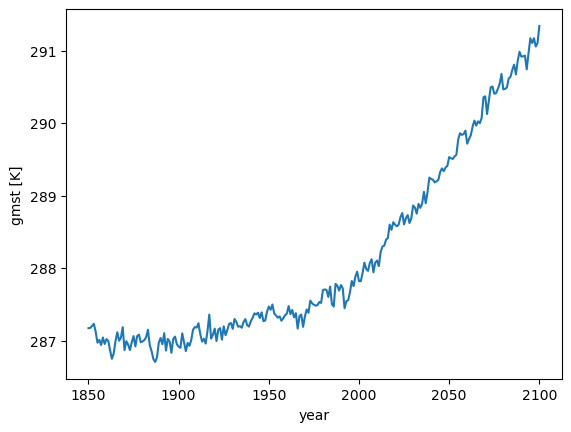

In [11]:
annual_gmst.plot()

## Linear regression - precipitation vs GMST

In [12]:
pr_vs_gmst = da_pr.assign_coords(gmst=('year', annual_gmst.data)).swap_dims({'year': 'gmst'})

In [13]:
fit = pr_vs_gmst.polyfit(dim='gmst', deg=1)

In [15]:
slope = fit.polyfit_coefficients.sel(degree=1)
intercept = fit.polyfit_coefficients.sel(degree=0)

In [16]:
slope_pct = (slope / da_pr_ave) * 100

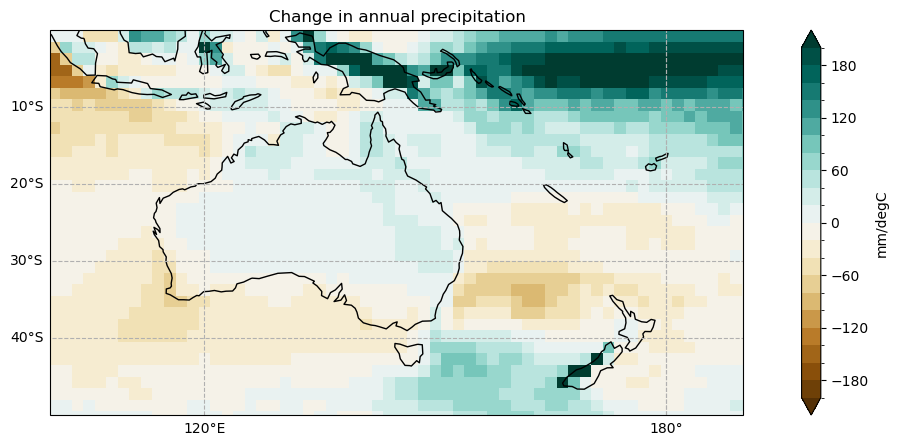

In [18]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))
slope.sel({'season': 'Annual'}).plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(-200, 201, 20),
    extend='both',
    cmap='BrBG',
    cbar_kwargs={'label': 'mm/degC'},
)
ax1.coastlines()
#ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
ax1.set_title('Change in annual precipitation')

plt.show()

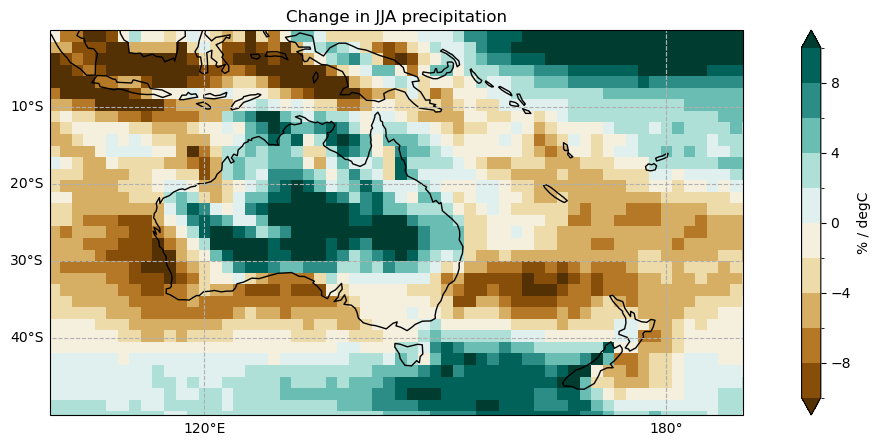

In [21]:
season = 'JJA'

fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))
slope_pct.sel({'season': season}).plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(-10, 10.1, 2),
    extend='both',
    cmap='BrBG',
    cbar_kwargs={'label': '% / degC'},
)
ax1.coastlines()
#ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
ax1.set_title(f'Change in {season} precipitation')

plt.show()